In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
from scipy.stats import linregress
import statsmodels.formula.api as smf

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


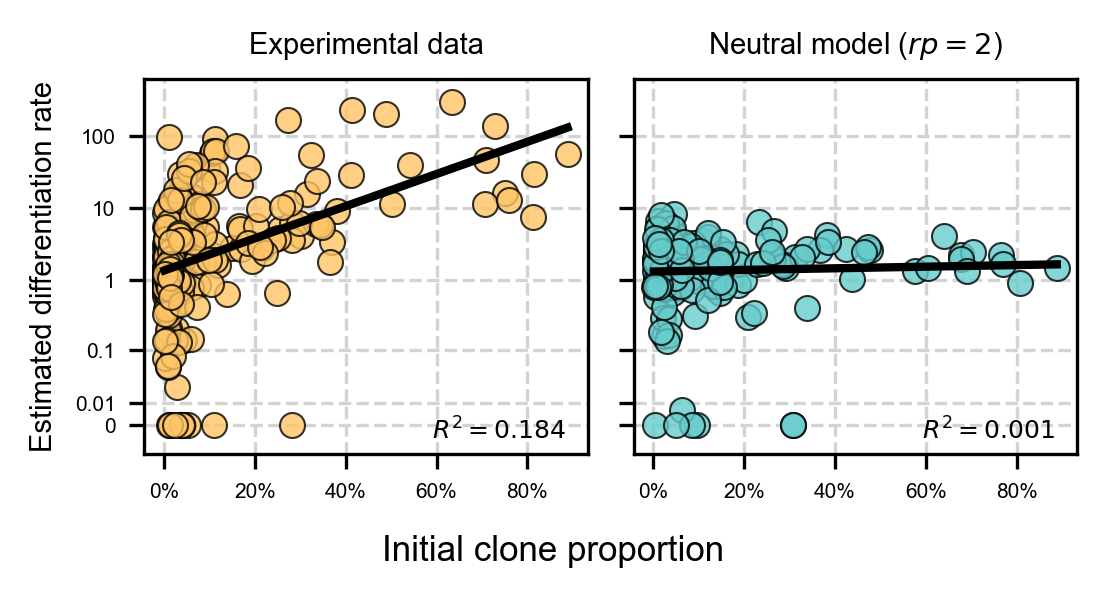

In [3]:
plt.rcParams.update(small_label_settings)

exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

dep_var = 'symlog10_r'

exp_df = df.query('scenario == @exp_scenario and ~r_opt.isna()').copy()
sim_df  = df.query('scenario == @sim_scenario and ~r_opt.isna() and duplicate == 0').copy()

# Fit regressions
slope_exp, intercept_exp, r_exp, p_exp, stderr_exp = linregress(exp_df['init_freq'], exp_df['symlog10_r'])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim_df['init_freq'], sim_df['symlog10_r'])

# X values for smooth line
x_exp = np.linspace(exp_df['init_freq'].min(), exp_df['init_freq'].max(), 200)
x_sim = np.linspace(sim_df['init_freq'].min(), sim_df['init_freq'].max(), 200)

# Predicted values
y_exp = intercept_exp + slope_exp * x_exp
y_sim = intercept_sim + slope_sim * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(3.7, 2), dpi = 300, sharey=True)

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=1$': hue(1),
    'Exp. data': exp_hue
}

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 

line_color = 'black'

# Experimental scenario
axes[0].scatter(exp_df['init_freq'], exp_df['symlog10_r'], color = exp_hue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_exp, y_exp, color=line_color, linewidth=2)
axes[0].set_title('Experimental data')

# Simulation scenario
axes[1].scatter(sim_df['init_freq'], sim_df['symlog10_r'], color = hue(2.5), alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[1].set_title("Neutral model ($rp=2$)")

axes[0].set_ylabel("Estimated differentiation rate")
# Y-axis ticks
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
axes[0].set_ylim([-0.4, 4.8])
axes[0].set_yticks(tick_symlog)
axes[0].set_yticklabels([str(r) for r in tick_r])

axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

fig.supxlabel("Initial clone proportion", y=0.05)

# Annotate R^2 values at bottom right of each axis
axes[1].text(0.95, 0.025, f"$R^2 = {r_sim**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=6)
axes[0].text(0.95, 0.025, f"$R^2 = {r_exp**2:.3f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=6)

plt.tight_layout()

filepath = os.path.join('images', 'correlation.svg')
plt.savefig('./images/correlation.svg', bbox_inches = 'tight', pad_inches = 0)

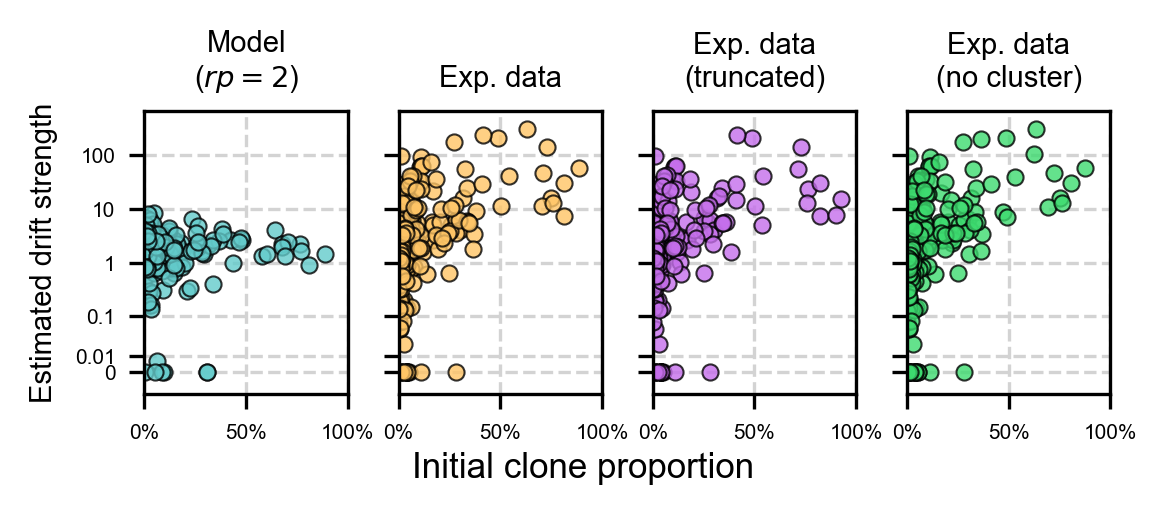

In [31]:
plt.rcParams.update(small_label_settings)

supplement_mode = True

if supplement_mode:
    scenarios = ['r36_rp2_mimic', 'full_pipeline', 'full_pipeline_trunc', 'no_collapse']
    labels = ['Model\n($rp=2$)', 'Exp. data', 'Exp. data\n(truncated)', 'Exp. data\n(no cluster)']
    fig, ax = plt.subplots(1, 4, figsize = (3.9, 1.8), dpi = 300, sharey = True)    
    filepath = os.path.join('images', 'correlation_supplement.svg')
else:
    scenarios = ['r36_rp2_mimic', 'full_pipeline']
    labels = ['Model ($rp=2$)', 'Exp. data']
    fig, ax = plt.subplots(1, 2, figsize = (3.7, 2), dpi = 300)    
    filepath = os.path.join('images', 'correlation.svg')

df2 = df.query('scenario.isin(@scenarios) and duplicate == 0')

palette = {
    'Model\n($rp=0$)': hue(0),
    'Model\n($rp=2$)': hue(2),
    'Exp. data': exp_hue,
    'Exp. data\n(truncated)': trunc_hue,
    'Exp. data\n(no cluster)': no_collapse_hue,
}

for i, (scenario, label) in enumerate(zip(scenarios, labels)):
    df3 = df2.query('scenario == @scenario')
    ax[i].scatter(df3['init_freq'], df3['symlog10_r'], color = palette[label], alpha=0.8,
                  edgecolor="black", linewidth=0.5, s = 15)
    # axes[i].plot(x_exp, y_exp, color=line_color, linewidth=2)
    ax[i].set_title(label)
    ax[i].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    # ax[i].text(0.95, 0.025, f"$R^2 todo$",
    #          transform=ax[i].transAxes, ha='right', va='bottom', fontsize=6)
    ax[i].grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax[i].set_axisbelow(True) 
    ax[i].set_xlim([0, 1])

ax[0].set_ylabel("Estimated drift strength")

tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
ax[0].set_ylim([-0.4, 4.8])
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax[0].set_yticks(tick_symlog)
ax[0].set_yticklabels([str(r) for r in tick_r])

fig.supxlabel("Initial clone proportion", y=0.1)

plt.tight_layout()
plt.subplots_adjust(wspace=0.25)   # smaller = tighter spacing

plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

In [35]:
def linear_mm(df, exp_scenario, sim_scenario, sim_duplicate):
    df2 = df[
        (df['scenario'] == exp_scenario) |
        ((df['scenario'] == sim_scenario) & (df['duplicate'] == sim_duplicate))
    ].copy()

    # Set scenario as categorial and re-order.
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )
    
    # Center data
    df2['init_freq_c'] = df2['init_freq']  - df2['init_freq'].mean()
    df2['log_r_c']     = df2['symlog10_r'] - df2['symlog10_r'].mean()

    model = smf.mixedlm(
        "log_r_c ~ init_freq_c * scenario",
        data=df2,
        groups=df2["fish"],
        re_formula="~1"
    ).fit(method="lbfgs")
    return model, df2

In [41]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

model, df2 = linear_mm(df, exp_scenario, sim_scenario, 0)
model.summary()

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
================================================================================
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          451             Method:                     REML     
No. Groups:                24              Scale:                      0.4145   
Min. group size:           5               Log-Likelihood:             -456.6539
Max. group size:           30              Converged:                  Yes      
Mean group size:           18.8                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.105    0.066 -1.578 0.115 -0.235  0.025
scenario[T.full_pipeline]              0.227    0.063  3.591 0.000  0.103  0.352
init_freq_c                            0.037    0.267  0.137 0.891 -0.487  0.560
init_freq_c:scenario[T.full_pipeline]  2.156    0.360  5.996 0.000  1.452  2.861
Group Var                              0.043    0.032                           
================================================================================

"""

In [37]:
print(f"The significance of initial frequency on simulated data is {model.pvalues['init_freq_c']:.3g}.")
print(f"The significance of interaction on initial frequency is {model.pvalues['init_freq_c:scenario[T.full_pipeline]']:.3g}.")

The significance of initial frequency on simulated data is 0.891.
The significance of interaction on initial frequency is 2.02e-09.


In [45]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df['duplicate'].unique():
    model, df2 = linear_mm(df, exp_scenario, sim_scenario, d)
    interact_p = model.pvalues[f'init_freq_c:scenario[T.{exp_scenario}]']
    sim_p = model.pvalues['init_freq_c']
    
    # print(f'For duplicate {d}, the simulation p is {sim_p:.3g} and the interaction p is {interact_p:.3g}.')
    row = {'Duplicate': d, 'simulation p': sim_p, 'interaction p': interact_p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.p

,Duplicate,simulation p,interaction p
0,0,0.890956,2.018946e-09
1,1,0.732254,1.274339e-10
2,2,0.527924,2.631185e-11
3,3,0.250768,1.138285e-12
4,4,0.786000,2.984504e-09
5,5,0.003621,9.303113e-17
6,6,0.284720,4.724715e-12
7,7,0.876685,3.671326e-09
8,8,0.433320,8.594143e-12
9,9,0.660251,7.875268e-11
